# 排名稳定性（按季度滚动）

回答"日内波动报表排在前面的证券，是一直靠前，还是只在某一段时间突出"。
做法：用 `日内波动报表` 同一套计算跑完整个历史区间，再按季度（或月、年）切开，每段单独打分排名（决策 0014）。

**用法**：改下面参数单元格（证券、区间、分段方式），然后 *Run → Run All Cells*。
第一次计算全部历史要几分钟到十几分钟；算完会存一份缓存（`reports/stability_cache/`），参数不变时再运行几秒钟就好。

In [1]:
# ===== 参数 =====
from trader.analytics import ReportParams

tickers = [
    "NVDA", "AMD", "TSLA", "AAPL", "META", "AMZN", "GOOG", "MSFT", "SMH", "IWM",
    "DIA", "GLD", "TLT", "XLE", "XLF", "KORU", "NVDL", "TSLL", "METU", "SNDK",
]  # fmt: skip
start_date = "2024-01-02"  # 本地数据最早从 2024-01-02 开始；开头 21 个交易日用来算 ADR，不参与汇总
end_date = "2026-10-15"

freq = "Q"  # 分段：Q = 季度，M = 月，Y = 年
# 某只证券在某段里有效天数少于这个数就不参加这一段（季度约 63 天，月度请改成 12 左右）
min_days = 30
top_n = 6  # "前几名"的口径
lookback = 1  # 选股检验：用过去几段的平均评分选前 top_n

params = ReportParams(
    benchmark_tickers=("SPY", "QQQ"),
    score_k=0.25,
    swing_skip_open_min=5,
    include_extended_hours=False,  # 本分析用不到扩展时段，关掉省时间
)
use_cache = True  # False = 不用缓存，重新计算

In [2]:
import hashlib
import pickle

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from trader.analytics import build_report, stability
from trader.analytics import report as R
from trader.config import project_dir


def show(fig):
    display(fig)
    plt.close(fig)


key = hashlib.sha1(repr((sorted(tickers), start_date, end_date, params)).encode()).hexdigest()[:12]
cache = project_dir() / "reports" / "stability_cache" / f"{start_date}_{end_date}_{key}.pkl"
if use_cache and cache.exists():
    rep = pickle.loads(cache.read_bytes())
    print(f"读取缓存 {cache.name}")
else:
    rep = build_report(tickers, start_date, end_date, params)
    rep.history = None  # 不存数据库连接
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_bytes(pickle.dumps(rep))
    print(f"计算完成，已存缓存 {cache.name}")
for note in rep.notes:
    display(Markdown(f"> ⚠ {note}"))

pr = stability.period_rankings(rep, freq, min_days=min_days)
summary = stability.stability_summary(pr, top_n=top_n)
periods = sorted(pr["period"].unique())
print(f"{rep.start} ~ {rep.end}，共 {len(periods)} 段：{', '.join(periods)}")

计算完成，已存缓存 2024-01-02_2026-10-15_b49ae203b709.pkl
2024-01-02 ~ 2026-10-15，共 11 段：2024Q1, 2024Q2, 2024Q3, 2024Q4, 2025Q1, 2025Q2, 2025Q3, 2025Q4, 2026Q1, 2026Q2, 2026Q3


## 1. 各段名次一览

每一格是这只证券在这一段里的名次（可交易性评分，段内排名，含 SPY、QQQ）。颜色越深越靠前；空格表示那一段没有参加
（还没上市，或有效天数不足 `min_days`）。行按下面第 2 部分的"评分中位数"排序。

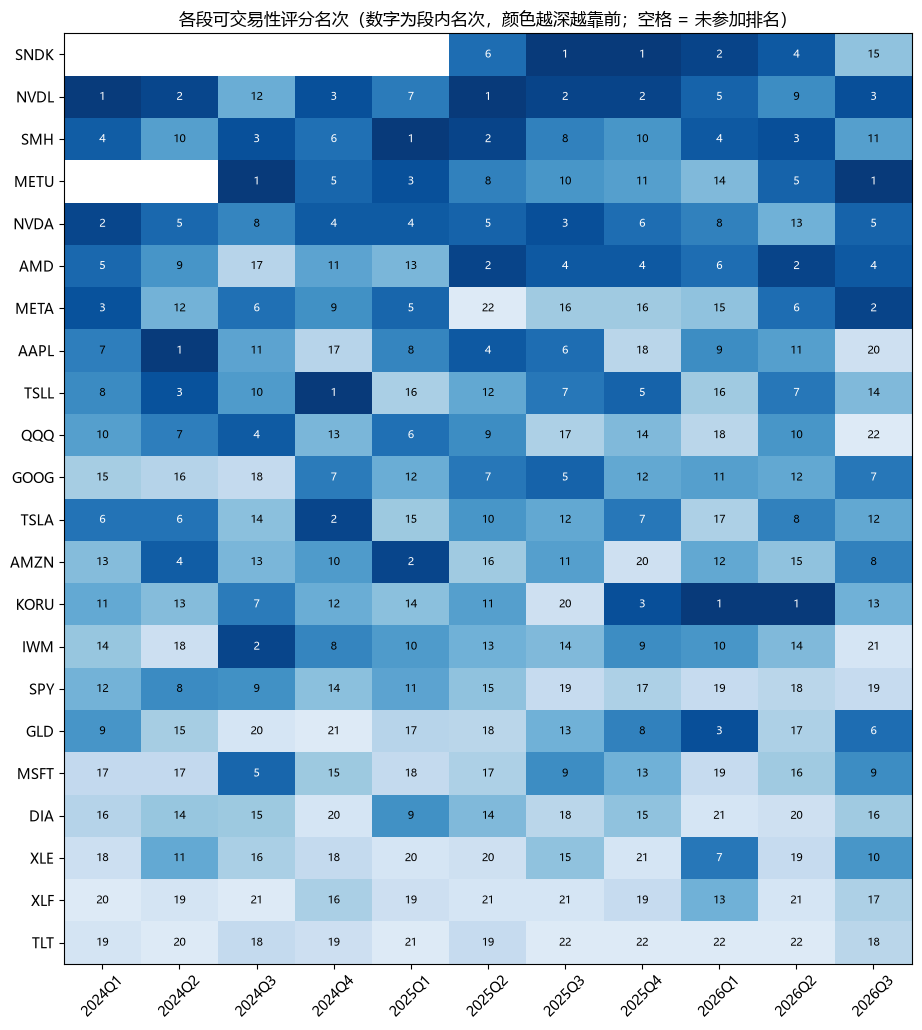

In [3]:
show(R.fig_period_ranks(pr, list(summary.index)))

## 2. 稳定性汇总（每只证券一行）

| 列 | 含义 |
|---|---|
| periods | 参加排名的段数 |
| score_median / score_mean / score_min | 各段评分（0–100，段内相对分数）的中位数、均值、最差一段 |
| rank_median / rank_best / rank_worst | 各段名次的中位数、最好、最差 |
| top_share | 进入前 top_n 名的段数占比 |
| bottom_half_share | 落到后一半的段数占比 |
| last_rank | 最近一段的名次 |
| capturable_mean | 各段"可获取波动均值"（%/天）的中位数——绝对值，可以跨段比较 |
| conversion | 各段转化效率的中位数 |

**怎么读**：score_median 高、top_share 高、bottom_half_share 接近 0 的是"一直靠前"；
rank_best 很好但 rank_worst 很差的是"时好时坏"。

In [4]:
fmt = {
    "score_median": "{:.1f}", "score_mean": "{:.1f}", "score_min": "{:.1f}",
    "rank_median": "{:.1f}", "rank_best": "{:.0f}", "rank_worst": "{:.0f}", "last_rank": "{:.0f}",
    "top_share": "{:.0%}", "bottom_half_share": "{:.0%}",
    "capturable_mean": "{:.2f}", "conversion": "{:.2f}",
}  # fmt: skip
display(
    summary.style.format(fmt, na_rep="-")
    .background_gradient(subset=["score_median", "top_share"], cmap="Greens")
    .background_gradient(subset=["bottom_half_share"], cmap="Reds")
)

,periods,score_median,score_mean,score_min,rank_median,rank_best,rank_worst,top_share,bottom_half_share,last_rank,capturable_mean,conversion,benchmark
symbol,,,,,,,,,,,,,
SNDK,6,91.7,79.9,35.7,3.0,1,15,83%,17%,15,3.05,0.55,False
NVDL,11,84.8,78.8,54.5,3.0,1,12,73%,9%,3,3.01,0.46,False
SMH,11,76.2,69.4,47.1,4.0,1,11,64%,0%,11,0.92,0.47,False
METU,9,73.0,67.6,36.2,5.0,1,14,56%,11%,1,1.73,0.40,False
NVDA,11,71.0,71.1,45.7,5.0,2,13,73%,9%,5,1.45,0.43,False
AMD,11,68.4,64.7,27.5,5.0,2,17,64%,27%,4,1.32,0.38,False
META,11,61.5,55.4,22.9,9.0,2,22,45%,45%,2,0.96,0.39,False
AAPL,11,58.1,53.7,19.5,9.0,1,20,27%,36%,20,0.73,0.41,False
TSLL,11,58.0,59.8,35.2,8.0,1,16,27%,36%,14,2.63,0.37,False


## 3. 排名能延续多久

**相邻两段的名次相关系数**（Spearman）：1 = 排名完全不变，0 = 上一段的排名对下一段没有参考价值。
**相隔 n 段的平均相关系数**：看排名的"记忆"能维持几段。

In [5]:
adj = stability.adjacent_rank_corr(pr)
display(adj.to_frame().style.format("{:.2f}").background_gradient(cmap="RdYlGn", vmin=-1, vmax=1))
print(f"相邻两段平均：{adj.mean():.2f}")
display(stability.lagged_rank_corr(pr).to_frame().style.format("{:.2f}"))

,spearman
2024Q1→2024Q2,0.68
2024Q2→2024Q3,0.22
2024Q3→2024Q4,0.42
2024Q4→2025Q1,0.44
2025Q1→2025Q2,0.50
2025Q2→2025Q3,0.74
2025Q3→2025Q4,0.59
2025Q4→2026Q1,0.55
2026Q1→2026Q2,0.49
2026Q2→2026Q3,0.33


相邻两段平均：0.50


,spearman_mean
lag,
1,0.50
2,0.49
3,0.41
4,0.45


## 4. 用上一段的排名选股票池，下一段还管用吗

每一段：按过去 `lookback` 段的平均评分选前 `top_n` 只（不含 SPY、QQQ），看它们在这一段的表现。

| 列 | 含义 |
|---|---|
| picked | 选中的证券 |
| next_score / all_score | 选中证券在这一段的平均评分 / 全部证券的平均评分 |
| next_rank | 选中证券在这一段的平均名次 |
| next_capturable / all_capturable | 选中证券 / 全部证券这一段的可获取波动均值（%/天） |
| hit | 选中的 top_n 只里，这一段仍在前 top_n 的只数 |

next_score 稳定高于 all_score，说明"按最近排名定股票池"是有用的（股票池规范计划每 20–30 个交易日刷新一次）。

In [6]:
for lb in sorted({1, lookback, 2}):
    sel = stability.selection_check(pr, lookback=lb, top_n=top_n)
    a, b, h = sel["next_score"].mean(), sel["all_score"].mean(), sel["hit"].mean()
    display(
        Markdown(
            f"**lookback = {lb}**：平均 next_score {a:.1f}，all_score {b:.1f}，"
            f"平均命中 {h:.1f}/{top_n}"
        )
    )
    display(
        sel.style.format(
            {
                "next_score": "{:.1f}",
                "next_rank": "{:.1f}",
                "all_score": "{:.1f}",
                "next_capturable": "{:.2f}",
                "all_capturable": "{:.2f}",
            }
        )
    )

**lookback = 1**：平均 next_score 65.5，all_score 50.6，平均命中 3.2/6

,picked,next_score,next_rank,all_score,next_capturable,all_capturable,hit
period,,,,,,,
2024Q2,NVDL NVDA META SMH AMD TSLA,64.0,7.3,48.5,1.55,0.98,3
2024Q3,AAPL NVDL TSLL AMZN NVDA TSLA,53.8,11.3,48.3,1.78,1.10,0
2024Q4,METU IWM SMH MSFT META KORU,57.5,9.2,50.8,0.86,1.13,2
2025Q1,TSLL TSLA NVDL NVDA METU SMH,62.8,7.7,49.2,2.14,1.17,4
2025Q2,SMH AMZN METU NVDA META NVDL,57.9,9.0,50.2,2.19,1.83,3
2025Q3,NVDL AMD SMH AAPL NVDA SNDK,81.9,4.0,52.5,1.31,0.78,5
2025Q4,SNDK NVDL NVDA AMD GOOG AAPL,67.5,7.2,51.2,1.80,1.13,4
2026Q1,SNDK NVDL KORU AMD TSLL NVDA,71.0,6.3,52.2,2.83,1.43,4
2026Q2,KORU SNDK GLD SMH NVDL AMD,75.4,6.0,51.0,2.61,1.47,4


**lookback = 2**：平均 next_score 64.1，all_score 50.9，平均命中 3.1/6

,picked,next_score,next_rank,all_score,next_capturable,all_capturable,hit
period,,,,,,,
2024Q3,NVDL NVDA AAPL TSLA TSLL AMD,50.2,12.0,48.3,1.84,1.10,0
2024Q4,AAPL TSLL NVDL NVDA SMH AMZN,68.1,6.8,50.8,1.95,1.13,4
2025Q1,TSLL METU NVDL IWM NVDA SMH,64.8,6.8,49.2,1.97,1.17,4
2025Q2,NVDA SMH NVDL METU TSLL TSLA,63.0,6.3,50.2,2.85,1.83,3
2025Q3,SMH NVDL NVDA AAPL METU AMD,74.9,5.5,52.5,1.04,0.78,4
2025Q4,NVDL SNDK AMD NVDA AAPL GOOG,67.5,7.2,51.2,1.80,1.13,4
2026Q1,SNDK NVDL AMD NVDA TSLL GOOG,62.9,8.0,52.2,1.89,1.43,3
2026Q2,SNDK KORU NVDL GLD AMD NVDA,68.3,7.7,51.0,2.53,1.47,3
2026Q3,KORU SNDK SMH AMD NVDL GLD,57.1,8.7,52.7,1.36,0.94,3


## 5. 可获取波动的绝对值（各段）

评分是段内相对的；这里是"可获取波动均值"（%/天，0.25 ADR 阈值、开盘 5 分钟后）的原始值，
能看出整体市场环境的变化（例如 2025 年 4 月关税行情）。

In [7]:
cap = stability.pivot(pr, "capturable_mean").reindex(summary.index)
display(cap.style.format("{:.2f}", na_rep="").background_gradient(cmap="YlOrRd", axis=None))

period,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
symbol,,,,,,,,,,,
SNDK,,,,,,2.61,2.61,3.81,4.55,3.50,1.57
NVDL,5.39,3.33,3.05,3.01,3.34,3.97,1.95,2.36,1.91,2.30,1.68
SMH,0.92,0.80,1.23,0.74,1.31,1.90,0.56,0.91,1.10,1.56,0.81
METU,,,1.73,1.45,2.35,2.49,0.95,1.32,1.57,2.26,2.43
NVDA,2.23,1.59,1.63,1.45,1.77,2.10,0.93,1.19,0.97,1.07,0.87
AMD,1.30,1.32,1.05,0.89,1.17,2.30,1.16,2.09,1.48,2.55,1.47
META,1.08,0.87,0.96,0.76,1.20,1.29,0.42,0.62,0.83,1.16,1.19
AAPL,0.52,0.87,0.73,0.37,0.86,1.91,0.67,0.46,0.80,0.77,0.52
TSLL,1.46,2.88,3.08,5.53,2.40,4.23,1.88,2.78,1.60,2.63,1.40


## 6. 导出

`reports/stability_<起>_<止>_<分段>/` 下：period_rankings.csv（每段每只一行）、stability_summary.csv、selection_check.csv。

In [8]:
out = project_dir() / "reports" / f"stability_{rep.start}_{rep.end}_{freq}"
out.mkdir(parents=True, exist_ok=True)
pr.to_csv(out / "period_rankings.csv", index=False, encoding="utf-8-sig")
summary.to_csv(out / "stability_summary.csv", encoding="utf-8-sig")
sel = stability.selection_check(pr, lookback=lookback, top_n=top_n)
sel.to_csv(out / "selection_check.csv", encoding="utf-8-sig")
print(out)

C:\My_Works\DayTrader\DayTrader\reports\stability_2024-01-02_2026-10-15_Q
